# 데이터 시각화 기초 — Matplotlib · Seaborn
질문 → 차트 고르기 → 그리기 → 읽은 결과 한 문장

In [1]:
# ▶ 환경 준비 — Colab · VS Code 공통, 맨 처음 한 번 실행
import os, sys, platform, subprocess
IN_COLAB = 'google.colab' in sys.modules

def gpu_info():
    try:
        r = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           capture_output=True, text=True, timeout=10)
        return r.stdout.strip() or None
    except Exception:
        return None

GPU = gpu_info()
print('실행 위치:', 'Colab' if IN_COLAB else f'내 컴퓨터 ({platform.system()})')
print('GPU:', GPU or '없음 → CPU로 실행 (이 노트북은 CPU로도 충분해요)')

# (선택) pandas를 GPU로 — Colab GPU 런타임 또는 Linux/WSL에 cuDF가 있을 때만
USE_GPU_PANDAS = False          # True로 바꾸고 이 칸을 다시 실행
if USE_GPU_PANDAS and GPU:
    try:
        get_ipython().run_line_magic('load_ext', 'cudf.pandas')
        print('pandas → GPU(cuDF) 사용')
    except Exception as e:
        print('cuDF를 쓸 수 없어 일반 pandas로 실행:', type(e).__name__)

# 한글 글꼴: Colab은 나눔고딕 설치, 윈도우는 맑은 고딕, 맥은 애플고딕
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
if IN_COLAB:
    nanum = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if not os.path.exists(nanum):
        subprocess.run('apt-get -qq install -y fonts-nanum > /dev/null', shell=True)
    fm.fontManager.addfont(nanum)
    plt.rcParams['font.family'] = 'NanumGothic'
elif platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:                                   # 리눅스·WSL: 설치된 한글 글꼴 찾기
    ko = [f.name for f in fm.fontManager.ttflist if 'Nanum' in f.name or 'CJK KR' in f.name]
    if ko: plt.rcParams['font.family'] = ko[0]
plt.rcParams['axes.unicode_minus'] = False
print('한글 글꼴:', plt.rcParams['font.family'])

실행 위치: 내 컴퓨터 (Windows)
GPU: NVIDIA GeForce RTX 5070 Laptop GPU, 8151 MiB
한글 글꼴: ['Malgun Gothic']


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

tit = sns.load_dataset('titanic')
mpg = sns.load_dataset('mpg')
flights = sns.load_dataset('flights')

## ① 선(시계열) — 시간에 따라 어떻게 변했나?

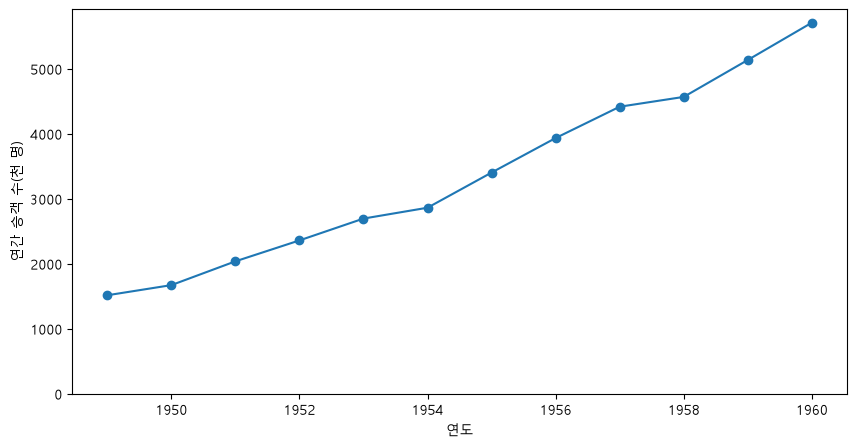

1520 → 5714


In [3]:
yearly = flights.groupby('year')['passengers'].sum()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly.index, yearly.values, marker='o')
ax.set_ylim(0); ax.set_xlabel('연도'); ax.set_ylabel('연간 승객 수(천 명)'); plt.show()
print(yearly.iloc[0], '→', yearly.iloc[-1])

## ② 히스토그램 — 값이 어디에 몰려 있나?

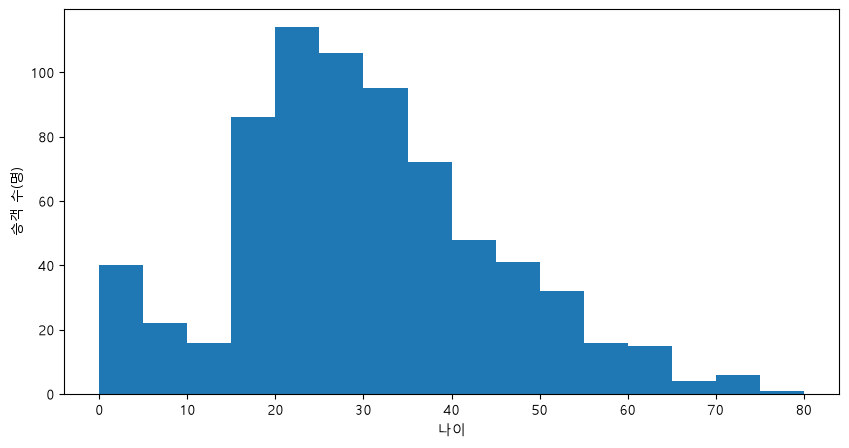

나이 빈칸: 177 / 891


In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(tit['age'].dropna(), bins=range(0, 85, 5))      # 5살 단위로 묶기
ax.set_xlabel('나이'); ax.set_ylabel('승객 수(명)'); plt.show()
print('나이 빈칸:', tit['age'].isna().sum(), '/', len(tit))

## ③ 박스플롯 — 그룹별 분포와 튀는 값은?

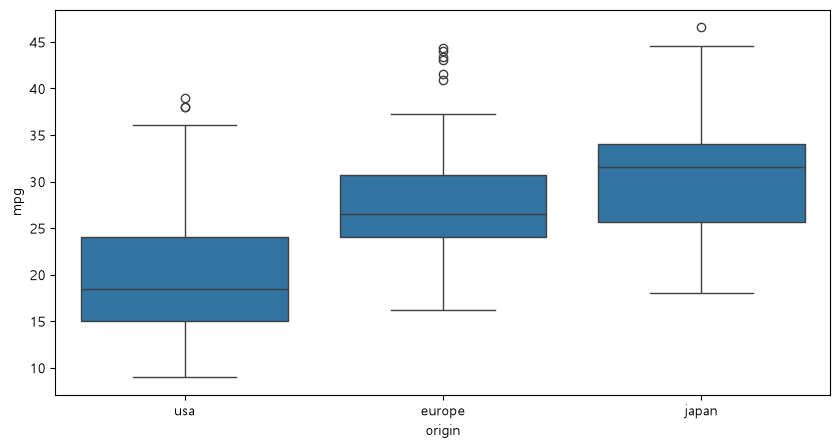

origin
europe    26.5
japan     31.6
usa       18.5
Name: mpg, dtype: float64


In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=mpg, x='origin', y='mpg', order=['usa', 'europe', 'japan'], ax=ax)
plt.show()
print(mpg.groupby('origin')['mpg'].median().round(1))

## ④ 막대 — 그룹끼리 크기를 비교하면?

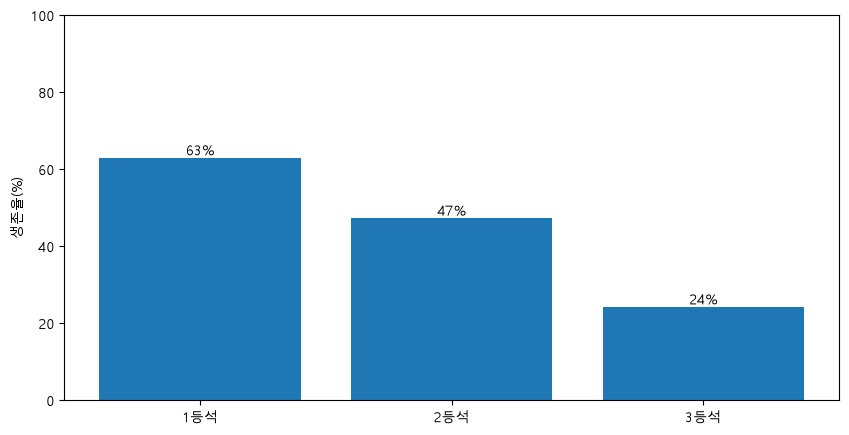

In [6]:
rate = tit.groupby('pclass')['survived'].mean() * 100      # 등급별 생존율(%)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(['1등석', '2등석', '3등석'], rate.values)
ax.bar_label(bars, fmt='%.0f%%'); ax.set_ylim(0, 100); ax.set_ylabel('생존율(%)'); plt.show()

## ⑤ 산점도 — 두 값이 함께 움직이나?

-0.831740933244335


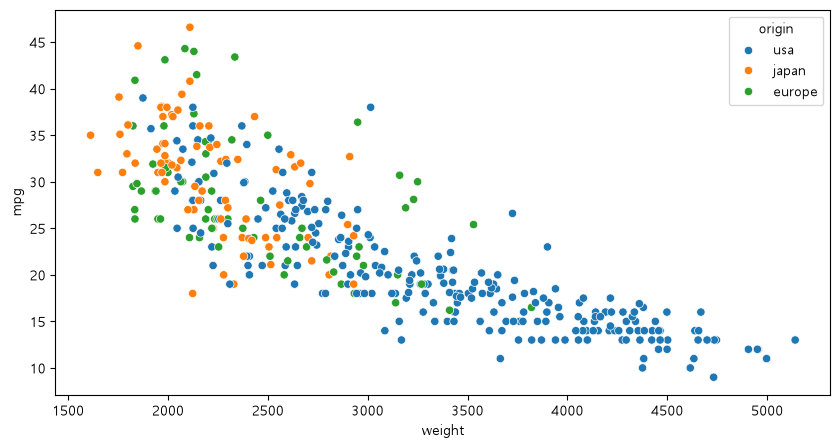

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=mpg, x='weight', y='mpg', hue='origin', ax=ax)      # hue = 색으로 나눌 열
print(mpg['weight'].corr(mpg['mpg']))                                  # 상관계수
plt.show()

## Matplotlib vs Seaborn — 같은 막대, 두 가지 방법

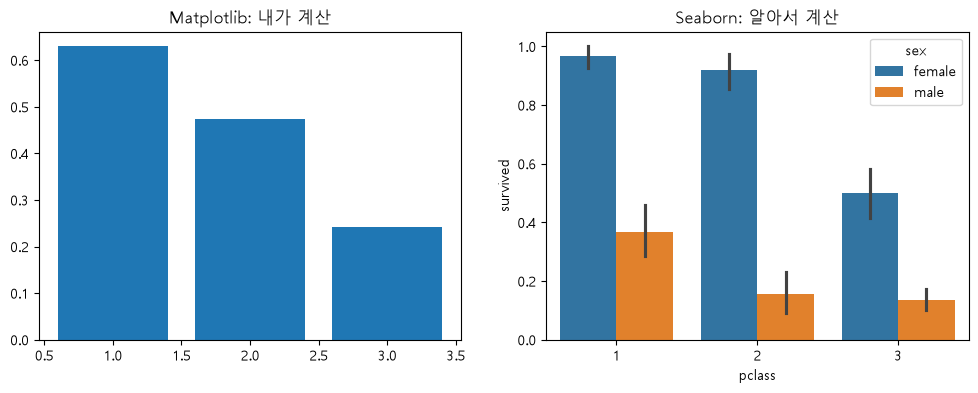

In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
r = tit.groupby('pclass')['survived'].mean()
a.bar(r.index, r.values); a.set_title('Matplotlib: 내가 계산')
sns.barplot(data=tit, x='pclass', y='survived', hue='sex', ax=b); b.set_title('Seaborn: 알아서 계산')
plt.show()

## 그림 파일로 저장하기 — `plt.show()` **앞에서** 저장

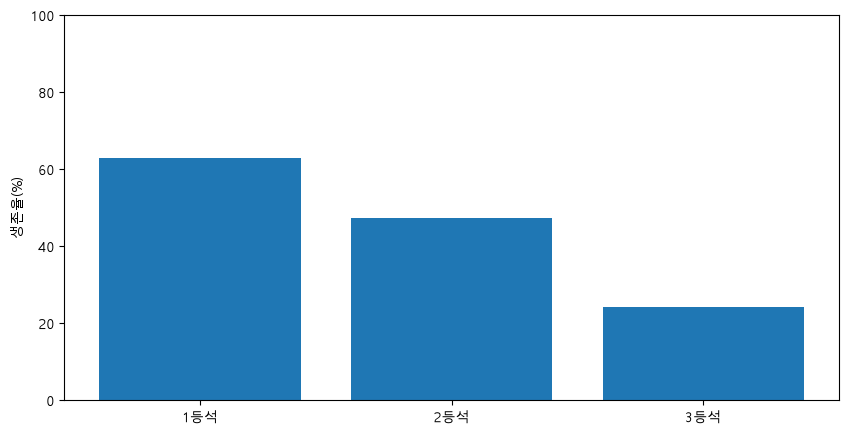

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(['1등석', '2등석', '3등석'], rate.values)
ax.set_ylim(0, 100); ax.set_ylabel('생존율(%)')
fig.savefig('class_survival.png', dpi=200, bbox_inches='tight')
plt.show()

## 연습: 데이터 3종 × 차트 3개
| 데이터 | 해 볼 차트 |
|---|---|
| 타이타닉 | 성별·등급별 생존율 → 막대 / 요금 분포 → 히스토그램 / 등급별 요금 → 박스플롯 |
| 대기오염 `data_air_2022.csv` | 날짜별 PM10 → 시계열 / PM2.5 분포 → 히스토그램 / NO2 vs PM2.5 → 산점도 |
| auto_mpg | 연식별 평균 연비 → 시계열 / 마력 vs 연비 → 산점도 / 실린더 수별 연비 → 박스플롯 |

차트마다 **질문 한 문장 → 그림 → 읽은 결과 한 문장**을 남기세요.

In [10]:
# 여기에 연습 코드를 써 보세요

## VS Code 제출 검수 및 재실행 오류 구분
- `sns.load_dataset()` 실패는 인터넷·원격 데이터 접근 문제일 수 있습니다. 연결 확인 후 제한적으로 재실행하고, 반복 실패하면 파일 기반 입력으로 전환합니다.
- `NameError`는 커널을 다시 시작했을 때 위 셀부터 `Run All`로 재실행합니다.
- 환경이 다른 경우 `ModuleNotFoundError`는 패키지 설치와 커널 선택을 수정해야 합니다.
- 미세먼지 연습용 `data_air_2022.csv`가 없다면 원본 수업 결과 대신 가상 결과를 실제인 것처럼 제출하지 않습니다.
- 실제 VS Code 전체 화면 스크린샷은 사용자 PC에서 실행 후 촬영해야 합니다.
